# Do engineered behavior features help us find churners?

**Governing question.** My earlier analysis of the Waze data suggested that *how* people use Waze matters more than *how much*: consistency beats intensity, and some very heavy drivers churn. I turned that into engineered features such as km per driving day, share of sessions in the last month, and a professional-driver flag. Notebook 04 added one more lead, a jump in risk above 200 drives a month. Do these features help a model **rank** users by churn risk better than the raw counts? And even if they don't, do they help a product manager **understand and target** users?

**Intended user.** A Waze product manager. Two uses matter: a better risk ranking, which means more churners reached for the same outreach budget, and clear behavioral segments that a retention campaign or product change can be aimed at.

**Evidence rules.** Development users only, with the same cross-validation folds as notebooks 02–04. The sealed test set stays closed. From this notebook on, figures use the course's **seaborn** style through the project's shared helpers in `dsm_project.visualization`.

**Road map.** §1 the features → §2 which behaviors separate churners (flags, ratios, distributions) → §3 why the features overlap → §4 evaluation design → §5 do they improve ranking? → §6 failure analysis → §7 what a PM can use → §8 decision.

## 1. The engineered features

The features live in `src/dsm_project/features.py` as `WazeFeatureBuilder`, a scikit-learn transformer, and are tested in `tests/test_features.py`. Three design choices matter:

- **Stateless:** every feature comes from the user's own row, so the transformer learns nothing during `fit` and cannot leak information across the train/test split.
- **Zero denominators give 0:** a user with no driving days has 0 km per driving day, never infinity. This matches the earlier analysis.
- **km per hour is excluded:** a quarter of users imply average speeds above 200 km/h (dataset card), so that ratio would mostly measure data errors.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import average_precision_score
from sklearn.model_selection import (
    RepeatedStratifiedKFold,
    StratifiedKFold,
    cross_val_predict,
    cross_val_score,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from dsm_project.algorithms import create_student_algorithm
from dsm_project.config import load_config
from dsm_project.data.waze import FEATURE_COLUMNS, WazeChurnAdapter
from dsm_project.experiments import split_supervised_task
from dsm_project.features import ENGINEERED_FEATURES, WazeFeatureBuilder, engineer_features
from dsm_project.visualization import (
    OUTCOME_PALETTE,
    plot_distributions_by_outcome,
    plot_rate_by_group,
    rate_by_group,
    set_theme,
)

set_theme()
config = load_config(Path("configs/waze.toml"))
dataset = WazeChurnAdapter().load(config)
split = split_supervised_task(dataset, config, task_name="classification")
dev_x, dev_y = split.train_features, split.train_targets
engineered = engineer_features(dev_x)
overall = dev_y.mean()

print(f"development users: {len(dev_x):,} | churn rate {overall:.3f}")
display(pd.DataFrame({"meaning": ENGINEERED_FEATURES}))

development users: 10,724 | churn rate 0.177


,meaning
share_sessions_last_month,sessions this month / lifetime sessions
lifetime_sessions_per_day,lifetime sessions / days since onboarding
km_per_driving_day,km driven this month / driving days
km_per_drive,km driven this month / drives
drives_per_driving_day,drives / driving days
sessions_per_active_day,sessions / active days
total_favorite_navigations,navigations to favorite places 1 + 2
share_sessions_to_favorites,favorite navigations / lifetime sessions
professional_driver,1 if 60+ drives and 15+ driving days this month
heavy_driver,1 if more than 200 drives this month


## 2. Which behaviors separate churners?

### 2.1 Flags: five yes/no user segments

For each flag we compare the churn rate of users with and without it. The whiskers are 95% Wilson confidence intervals for each rate, so a visible gap between whiskers is not a small-sample accident.

,users with flag,share of users,churn with flag,churn without
flag,,,,
professional_driver,1876,0.175,0.073,0.199
low_driving_frequency,2702,0.252,0.346,0.120
high_driving_frequency,2307,0.215,0.052,0.212
heavy_driver,546,0.051,0.260,0.173
high_recent_usage,3490,0.325,0.185,0.174


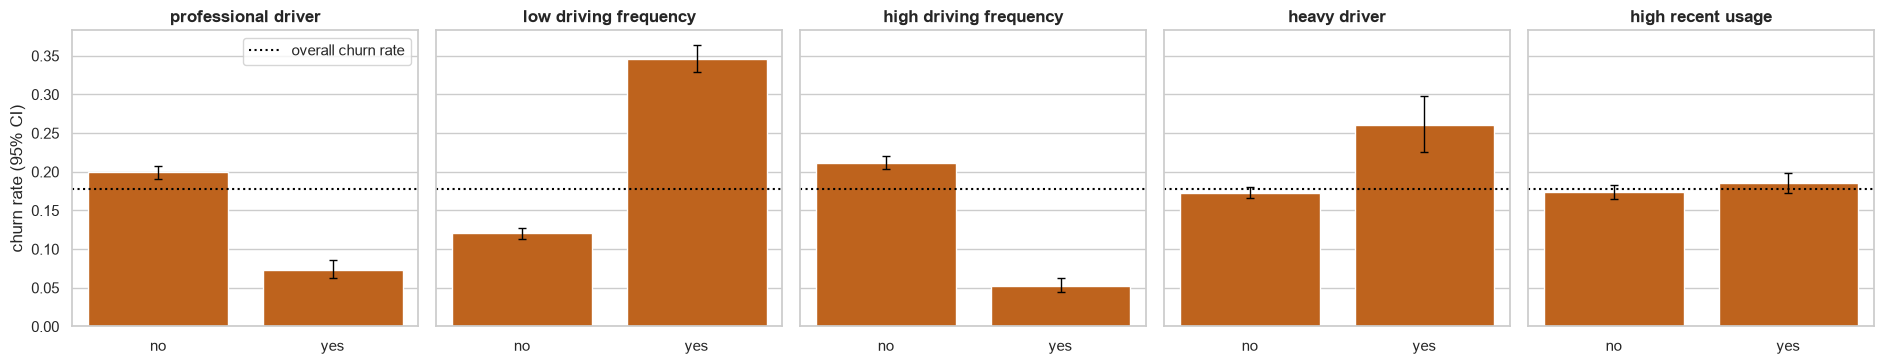

In [2]:
flags = ["professional_driver", "low_driving_frequency", "high_driving_frequency",
         "heavy_driver", "high_recent_usage"]
fig, axes = plt.subplots(1, len(flags), figsize=(19, 3.8), sharey=True)
flag_rows = []
for ax, flag in zip(axes, flags, strict=True):
    table = rate_by_group(dev_y, engineered[flag].map({0: "no", 1: "yes"}))
    plot_rate_by_group(table, overall_rate=overall, ax=ax, title=flag.replace("_", " "))
    if ax is not axes[0]:
        ax.set_ylabel("")
        ax.get_legend().remove()
    flag_rows.append({"flag": flag, "users with flag": int(table.loc["yes", "users"]),
                      "share of users": table.loc["yes", "users"] / len(dev_y),
                      "churn with flag": table.loc["yes", "rate"],
                      "churn without": table.loc["no", "rate"]})
plt.tight_layout()
display(pd.DataFrame(flag_rows).set_index("flag").round(3))

**Insights.**

- **Professional drivers** (60+ drives and 15+ driving days) churn at about 7%, against 20% for everyone else. That is about 1 in 6 users who rely on Waze as a work tool.
- **Low-frequency drivers** (5 or fewer driving days) churn at about 35%, about three times the rate of other users, and they are a quarter of the user base.
- **High-frequency drivers** (20+ driving days) churn at about 5%.
- **Heavy drivers** (more than 200 drives a month) churn at about 26% against 17%. Very intense use is *not* loyalty, which repeats the pattern from my earlier analysis and from notebook 04.
- **High recent usage** (60%+ of lifetime sessions in the last month) makes almost no difference, so recent spikes are not a churn signal on their own.

**Main takeaway: consistency, not intensity, separates loyal users from churners.**

### 2.2 Ratios: churn rate across quintiles

For the continuous features, we split users into five equal-sized groups (quintiles) and compare churn rates.

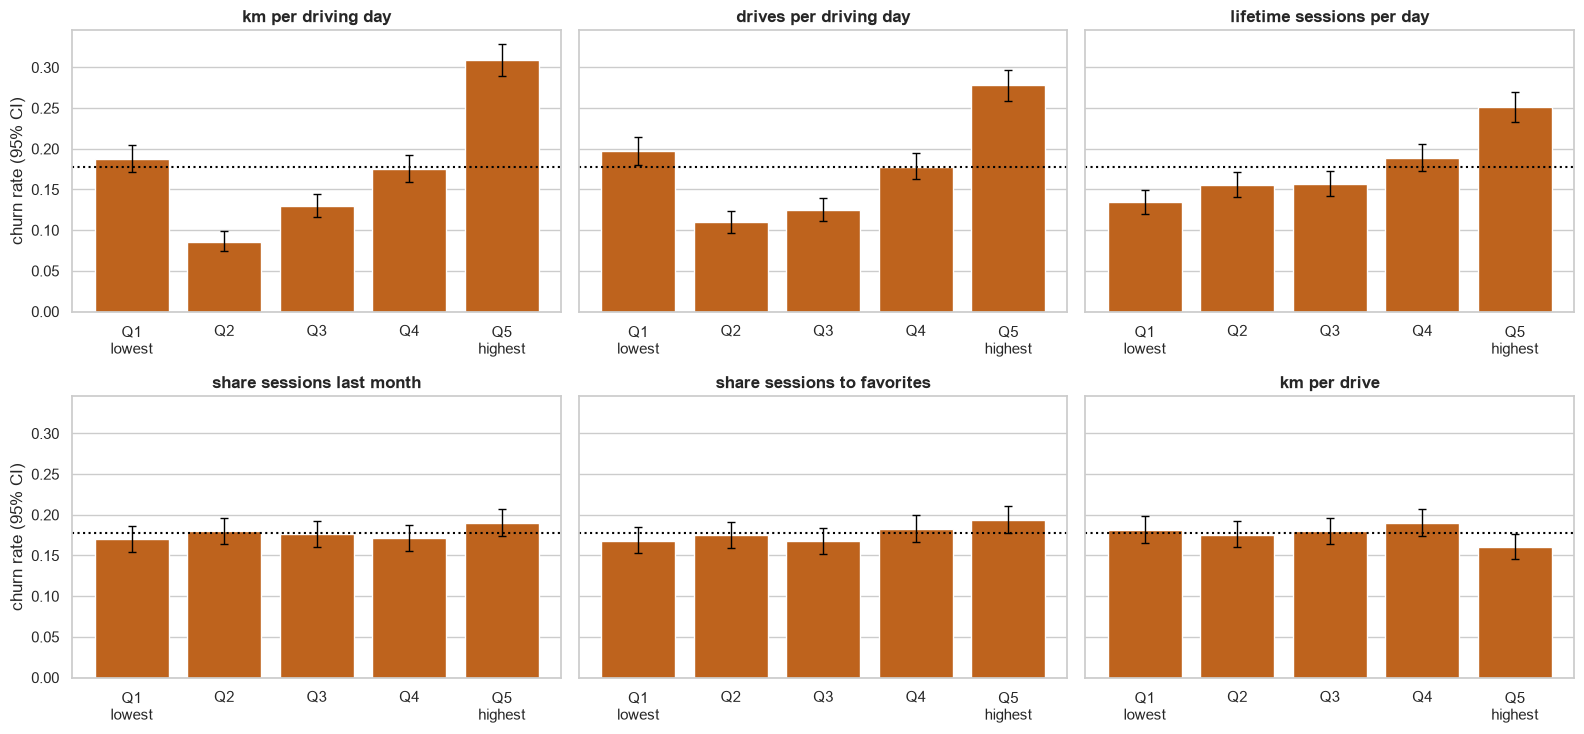

In [3]:
ratios = ["km_per_driving_day", "drives_per_driving_day", "lifetime_sessions_per_day",
          "share_sessions_last_month", "share_sessions_to_favorites", "km_per_drive"]
fig, axes = plt.subplots(2, 3, figsize=(16, 7.5), sharey=True)
for ax, feature in zip(axes.flat, ratios, strict=True):
    quintile = pd.qcut(engineered[feature].rank(method="first"), 5,
                       labels=["Q1\nlowest", "Q2", "Q3", "Q4", "Q5\nhighest"])
    plot_rate_by_group(rate_by_group(dev_y, quintile), overall_rate=overall, ax=ax,
                       title=feature.replace("_", " "))
    ax.get_legend().remove()
    if ax not in axes[:, 0]:
        ax.set_ylabel("")
plt.tight_layout()

**Insights.**

- **Driving intensity per active day** matters: the top fifth by km per driving day churns at about 31%, and the top fifth by drives per driving day at about 28%. Both are U-shaped, with the lowest risk in the second quintile.
- **Lifetime sessions per day rises with churn.** The top fifth churns at about 25% against 13% for the lowest. Users who packed many sessions into a short tenure are the "short-term heavy users" from my earlier analysis.
- **Share of sessions in the last month, share of sessions to favorites, and km per drive are nearly flat**, so they carry little churn signal on their own.

### 2.3 Distributions by outcome

Empirical CDFs show the whole distribution for each outcome without any smoothing choices: where the orange (churned) curve rises earlier, churned users have smaller values. The x-axes stop at the 99th percentile so the long tails don't hide the bulk of users.

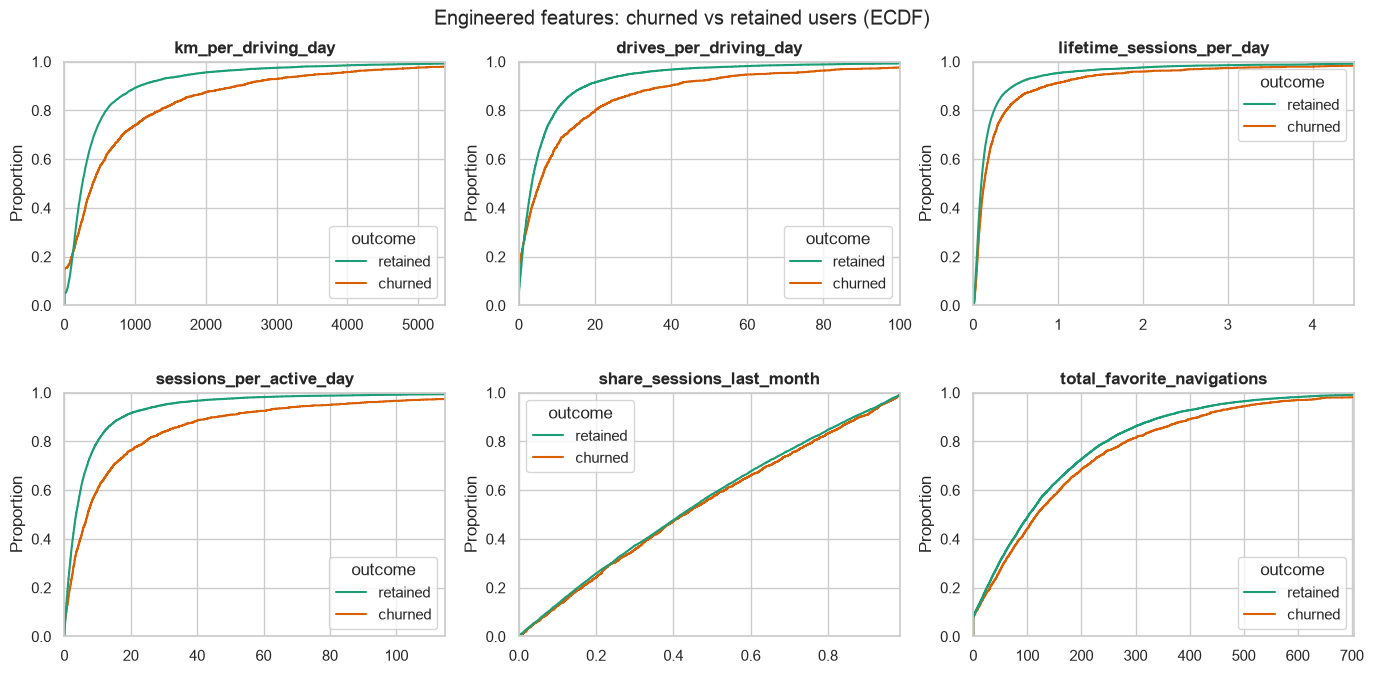

,development users
share of sessions in last month > 1 (lifetime total too small),14
favorite navigations exceed lifetime sessions,4098


In [4]:
show = ["km_per_driving_day", "drives_per_driving_day", "lifetime_sessions_per_day",
        "sessions_per_active_day", "share_sessions_last_month", "total_favorite_navigations"]
fig = plot_distributions_by_outcome(engineered, show, dev_y, kind="ecdf", columns=3)
for ax, feature in zip(fig.axes, show, strict=False):
    ax.set_xlim(0, engineered[feature].quantile(0.99))
    ax.set_xlabel("")
fig.suptitle("Engineered features: churned vs retained users (ECDF)", y=1.02)
plt.show()

quality = pd.Series({
    "share of sessions in last month > 1 (lifetime total too small)":
        int((engineered["share_sessions_last_month"] > 1).sum()),
    "favorite navigations exceed lifetime sessions":
        int((engineered["share_sessions_to_favorites"] > 1).sum()),
}, name="development users")
display(quality.to_frame())

The ECDFs agree with the quintile charts. Churned users spread toward *higher* km and drives per driving day and higher lifetime sessions per day, while the share of sessions in the last month barely differs.

**Data quality.** 14 users report more sessions this month than in their whole lifetime, which is impossible and comes from the synthetic generator (see the dataset card). And 4,098 development users (38%) have more favorite-place navigations than lifetime sessions. That is possible if one session can include several navigations, but it means `share_sessions_to_favorites` is really *navigations per session*, not a share. The ratio features inherit these quirks, one more reason not to over-read them.

## 3. Why the features overlap with what the models already see

An engineered feature only helps a model if it carries information the raw columns don't. The heat map shows rank (Spearman) correlations among the raw and engineered features. Rank correlation is used because many features have long tails.

,max |correlation| with a raw column
total_favorite_navigations,0.90
km_per_drive,0.80
sessions_per_active_day,0.77
share_sessions_to_favorites,0.76
drives_per_driving_day,0.70
share_sessions_last_month,0.69
lifetime_sessions_per_day,0.67
km_per_driving_day,0.56


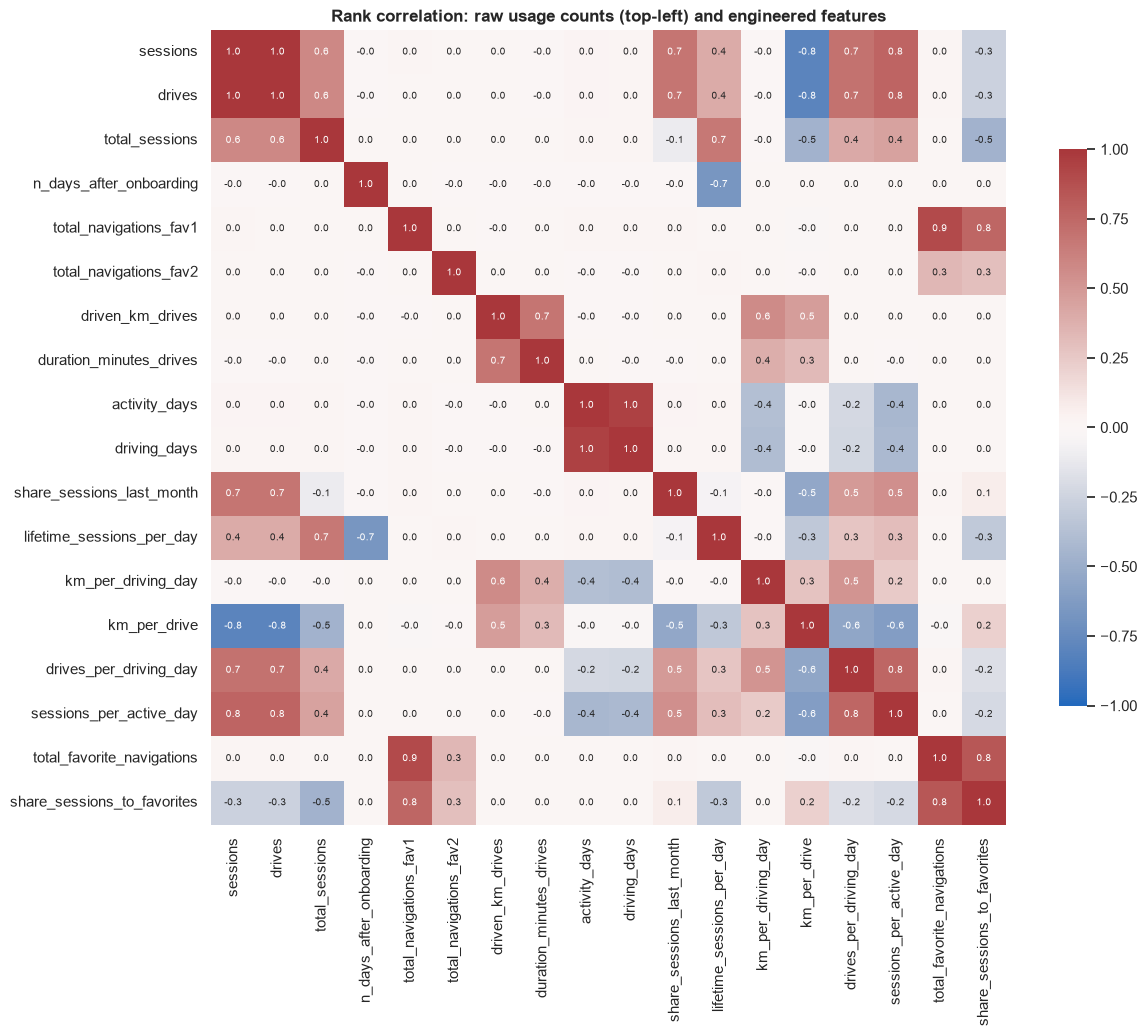

In [5]:
continuous = [c for c in ENGINEERED_FEATURES if c not in flags]
combined = pd.concat([dev_x[list(FEATURE_COLUMNS)].drop(columns="is_iphone"),
                      engineered[continuous]], axis=1)
correlation = combined.corr(method="spearman")

fig, ax = plt.subplots(figsize=(13, 10.5))
sns.heatmap(correlation, cmap="vlag", center=0, vmin=-1, vmax=1, square=True,
            annot=True, fmt=".1f", annot_kws={"size": 7}, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Rank correlation: raw usage counts (top-left) and engineered features")
plt.tight_layout()

strongest = (correlation.loc[continuous, [c for c in combined.columns if c not in continuous]]
             .abs().max(axis=1).sort_values(ascending=False))
display(strongest.round(2).rename("max |correlation| with a raw column").to_frame())

Most engineered features are strongly rank-correlated with at least one raw column. For example, drives per driving day moves with drives, and lifetime sessions per day with total sessions and tenure. A model that already sees the raw counts can largely reconstruct these ratios, which explains what §5 finds.

## 4. Evaluation design

- **Data and folds:** development users only, the same 5-fold splits as before. Paired comparisons repeat them 3 times (15 folds).
- **Metric:** average precision (AP). Raw-feature baselines: softmax ≈ 0.39, boosted stumps ≈ 0.39.
- **Candidates:** each model with the 11 raw features versus raw plus all 13 engineered features, and softmax with small targeted additions motivated by §2 and notebook 04 (the professional-driver flag; heavy-driver plus low-frequency flags; km per driving day).
- **Rule fixed in advance:** keep an engineered feature only if it raises mean paired AP by more than the fold-to-fold spread of the gain. Otherwise the simpler raw model wins.
- **Fairness:** the builder sits *inside* each pipeline, so it is applied separately within every fold. That doesn't matter for a stateless transform, but it is the correct habit.

## 5. Do the features improve ranking?

mean AP  gain vs raw  \
model          features                                              
softmax        raw only                        0.3915       0.0000   
               + all 13 engineered             0.3845      -0.0070   
               + professional driver           0.3920       0.0004   
               + heavy driver, low frequency   0.3918       0.0003   
               + km per driving day            0.3883      -0.0032   
boosted stumps raw only                        0.3926       0.0000   
               + all 13 engineered             0.3874      -0.0052   

                                              sd of gain  folds better  
model          features                                                 
softmax        raw only                           0.0000             0  
               + all 13 engineered                0.0077             2  
               + professional driver              0.0013             8  
               + heavy driver, low frequency      0.0044             6  
               + km per driving day               0.0079             7  
boosted stumps raw only                           0.0000             0  
               + all 13 engineered                0.0058             3

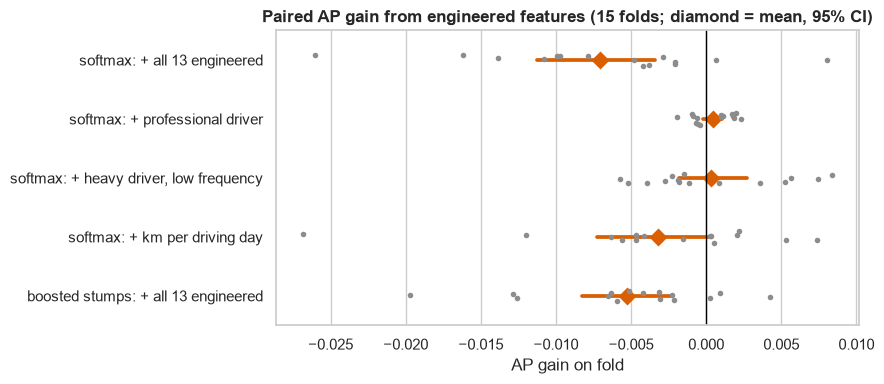

In [6]:
repeated = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=438)


def softmax(include=None, all_features=False):
    steps = []
    if all_features:
        steps.append(WazeFeatureBuilder())
    elif include:
        steps.append(WazeFeatureBuilder(include=include))
    return make_pipeline(*steps, StandardScaler(), create_student_algorithm(
        "softmax_regression", l2_penalty=0.1, learning_rate=0.5))


def stumps(all_features=False):
    model = create_student_algorithm("gradient_boosting", n_estimators=200,
                                     learning_rate=0.1, max_depth=1)
    return make_pipeline(WazeFeatureBuilder(), model) if all_features else model


candidates = {
    ("softmax", "raw only"): softmax(),
    ("softmax", "+ all 13 engineered"): softmax(all_features=True),
    ("softmax", "+ professional driver"): softmax(("professional_driver",)),
    ("softmax", "+ heavy driver, low frequency"): softmax(("heavy_driver", "low_driving_frequency")),
    ("softmax", "+ km per driving day"): softmax(("km_per_driving_day",)),
    ("boosted stumps", "raw only"): stumps(),
    ("boosted stumps", "+ all 13 engineered"): stumps(all_features=True),
}
fold_ap = {key: cross_val_score(model, dev_x, dev_y, cv=repeated, scoring="average_precision")
           for key, model in candidates.items()}

rows, gaps = [], []
for (family, variant), scores in fold_ap.items():
    gap = scores - fold_ap[(family, "raw only")]
    rows.append({"model": family, "features": variant, "mean AP": scores.mean(),
                 "gain vs raw": gap.mean(), "sd of gain": gap.std(),
                 "folds better": int((gap > 0).sum())})
    if variant != "raw only":
        gaps += [{"comparison": f"{family}: {variant}", "AP gain on fold": g} for g in gap]
display(pd.DataFrame(rows).set_index(["model", "features"]).round(4))

fig, ax = plt.subplots(figsize=(9, 4))
gaps = pd.DataFrame(gaps)
sns.stripplot(data=gaps, y="comparison", x="AP gain on fold", color="0.55", size=4, ax=ax)
sns.pointplot(data=gaps, y="comparison", x="AP gain on fold", color=OUTCOME_PALETTE["churned"],
              linestyle="none", errorbar=("ci", 95), markers="D", ax=ax)
ax.axvline(0, color="black", linewidth=1)
ax.set(ylabel="", title="Paired AP gain from engineered features (15 folds; diamond = mean, 95% CI)")
plt.tight_layout()

**Insights.**

- **Adding all 13 engineered features makes ranking slightly worse** for both model families: softmax loses about 0.007 AP and boosted stumps about 0.005. For softmax the 95% interval of the loss lies entirely below zero, so the drop is real, not fold noise. Many correlated inputs add noise to the fit without adding new information.
- **No targeted addition passes the rule.** Each gain is a few ten-thousandths of AP or negative, well inside the fold-to-fold spread. The professional-driver flag comes closest, but its gain is smaller than its own noise.
- This is consistent with §3: the raw activity, tenure, and drive counts already contain the signal these features re-express.

## 6. Failure analysis: do they reach the active churners?

The key failure in every notebook has been churners who were still active on more than 20 days. Could behavior *ratios* reveal them? We compare, at a 20% outreach budget, which churners the raw and enriched softmax models reach.

,raw features,+ all engineered
0–10 days,0.691,0.678
11–20 days,0.090,0.082
21–31 days,0.000,0.000
all churners,0.452,0.442


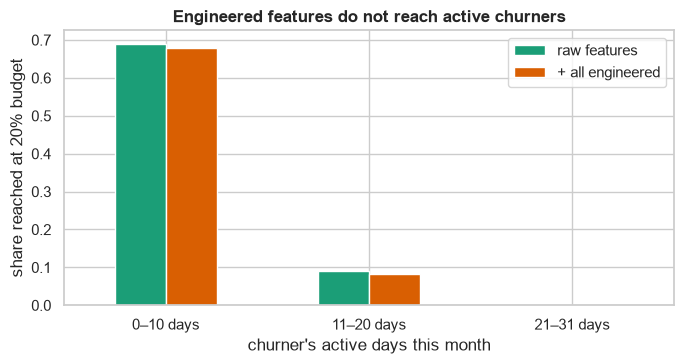

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=438)
churners = dev_y.to_numpy() == 1
activity = pd.cut(dev_x["activity_days"], [-1, 10, 20, 31],
                  labels=["0–10 days", "11–20 days", "21–31 days"]).to_numpy()
reach = {}
for label, model in (("raw features", softmax()), ("+ all engineered", softmax(all_features=True))):
    scores = cross_val_predict(model, dev_x, dev_y, cv=cv, method="predict_proba")[:, 1]
    flagged = scores >= np.quantile(scores, 0.8)
    row = pd.Series(flagged[churners]).groupby(activity[churners]).mean()
    row["all churners"] = flagged[churners].mean()
    reach[label] = row
reach = pd.DataFrame(reach)

ax = reach.drop(index="all churners").plot.bar(
    rot=0, figsize=(7, 3.8), color=[OUTCOME_PALETTE["retained"], OUTCOME_PALETTE["churned"]])
ax.set(xlabel="churner's active days this month", ylabel="share reached at 20% budget",
       title="Engineered features do not reach active churners")
plt.tight_layout()
display(reach.round(3))

They do not. Both versions reach about 69% of the least-active churners and none of those active on more than 20 days. The ratios describe the *style* of usage within one month, but an active user who is about to leave still looks like an active user who will stay. Seeing those users would need data this dataset does not have: changes over time, app ratings, or support contacts.

## 7. What a product manager can use

Even without improving the model, the engineered features are valuable as **plain-language segments**: they explain *who* churns in terms a PM can act on. The table summarizes the most useful ones.

In [8]:
segments = {
    "Professional drivers (60+ drives, 15+ driving days)": engineered["professional_driver"] == 1,
    "High-frequency drivers (20+ driving days)": engineered["high_driving_frequency"] == 1,
    "Low-frequency drivers (5 or fewer driving days)": engineered["low_driving_frequency"] == 1,
    "Heavy drivers (200+ drives)": engineered["heavy_driver"] == 1,
    "Long trips (top 20% km per driving day)":
        engineered["km_per_driving_day"] >= engineered["km_per_driving_day"].quantile(0.8),
    "Short tenure, heavy use (top 20% lifetime sessions per day)":
        engineered["lifetime_sessions_per_day"] >= engineered["lifetime_sessions_per_day"].quantile(0.8),
}
summary = pd.DataFrame([{
    "segment": name, "users": int(mask.sum()), "share of users": mask.mean(),
    "churn rate": dev_y[mask].mean(), "vs overall": dev_y[mask].mean() / overall,
    "share of all churners": dev_y[mask].sum() / dev_y.sum(),
} for name, mask in segments.items()]).set_index("segment")
display(summary.round(2))

,users,share of users,churn rate,vs overall,share of all churners
segment,,,,,
"Professional drivers (60+ drives, 15+ driving days)",1876,0.17,0.07,0.41,0.07
High-frequency drivers (20+ driving days),2307,0.22,0.05,0.30,0.06
Low-frequency drivers (5 or fewer driving days),2702,0.25,0.35,1.95,0.49
Heavy drivers (200+ drives),546,0.05,0.26,1.47,0.07
Long trips (top 20% km per driving day),2145,0.20,0.31,1.74,0.35
"Short tenure, heavy use (top 20% lifetime sessions per day)",2145,0.20,0.25,1.41,0.28


**How a PM could use this.**

- **Protect the core:** professional and high-frequency drivers are the most loyal groups. Changes that disrupt daily routines (navigation UI, ETA accuracy, commute features) carry the most risk for them.
- **Re-engage the occasional driver:** low-frequency drivers are a quarter of users with about twice the overall churn rate, and they account for close to half of all churners. Habit-building nudges, such as commute reminders or saved routes, are the natural experiment for them.
- **Investigate heavy and long-trip users:** these users drive a lot and still churn more often. Possible causes include long-route experience, battery or data costs, or professional users switching tools. That calls for user research, not just outreach.

These are hypotheses for experiments (A/B tests), not causal conclusions: the data are synthetic and observational.

## 8. Conclusion and decision

**Answer.** The engineered features turn my earlier insight, **consistency, not intensity, drives retention**, into clear, measurable segments with churn rates from about 5% to 35%. But they do **not** improve the churn ranking: adding them leaves average precision unchanged or slightly lower for both softmax regression and boosted stumps, because they re-express the raw activity, tenure, and drive counts the models already use. They also don't reach active churners.

**Decision.**

- **Models keep the 11 raw features.** Softmax regression and boosted stumps remain the finalists for model selection.
- **The engineered features go into the product as explanation.** They are the right language for the PM-facing app: each scored user can be shown with their segment, such as "low-frequency driver".
- `WazeFeatureBuilder` stays in the package, tested, for that purpose and for the segmentation work.

**Next steps.**

1. **Unsupervised segmentation (k-means and PCA):** do these behaviors form natural user groups without using the churn label, and how do churn rates differ across them?
2. **Linear SVM and a small neural network** (lectures 11–12), for course coverage and as further candidates.
3. **Model selection:** open the test set once for the finalists, with calibration and confusion-matrix checks.